# ARIMA: pronóstico semanal de WTI y Brent
## Período 2 · Desde el 1 de abril de 2026

Este notebook ajusta **un ARIMA independiente para WTI y otro para Brent**, utilizando exclusivamente el período 2 definido en el trabajo: **desde el 01/04/2026 hasta la fecha de referencia**. El período 1 y marzo de 2026 no participan del análisis, la selección del modelo ni la evaluación.

Se conserva el orden de exposición del notebook de series de tiempo: configuración, datos, limpieza, series, modelo, validación, pronóstico, residuos e interpretación. Cada punto explica qué hace el código y cómo leer sus resultados. El punto 10 agrega una prueba de una semana histórica elegible.

El objetivo es anticipar las cinco cotizaciones de **lunes a viernes de la semana siguiente**, en USD por barril. El contexto bélico es la motivación del recorte definido por el TP; este modelo univariado utiliza precios pasados y **no estima el efecto causal de la guerra ni incorpora noticias o variables geopolíticas**. Un único período también puede contener cambios de régimen.

**Uso:** ejecutar todas las celdas en orden. La fuente inicial es el CSV local para poder reproducir el análisis sin conexión ni clave. Se puede seleccionar EIA en el punto 1. Al ejecutar se muestran la fecha de referencia, el archivo utilizado, el último dato disponible y las versiones de las bibliotecas. El notebook no guarda ni sobrescribe los datos de origen.

In [1]:
from pathlib import Path
from inspect import signature
from itertools import product
import platform
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels
from IPython.display import Markdown, display
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

plt.style.use("seaborn-v0_8-whitegrid")
COLORES = {"WTI": "#2864A0", "Brent": "#D08023"}

## 1. Configuración de la próxima semana

`FUENTE_DATOS = "CSV"` selecciona la copia de `data/` con el mes más reciente en su nombre. `"EIA"` consulta los precios spot diarios con la clave local del proyecto. **La fuente elegida se informa y no se cambia automáticamente si falla.**

`FECHA_REFERENCIA = None` toma el día actual de Argentina; una fecha como `"2026-10-26"` permite reproducir un corte. Se descartan todos los precios posteriores a ese día. La semana objetivo siempre empieza el lunes siguiente, incluso si la ejecución ocurre un lunes.

Se exigen al menos **60 cotizaciones de entrenamiento**, se utilizan **tres cortes temporales** y se fija una significancia del **5 %**. Son decisiones iniciales del ejercicio, no garantías de precisión. El calendario futuro aproxima una publicación por día de lunes a viernes; no representa un calendario oficial de feriados.

In [2]:
PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "requirements.txt").is_file() and (p / "notebooks").is_dir()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Abrir el notebook desde la raíz del proyecto o notebooks/.")

FUENTE_DATOS = "CSV"          # Alternativa: "EIA" con la clave local del proyecto.
FECHA_REFERENCIA = None        # None = hoy en Argentina; o "AAAA-MM-DD".
INICIO_PERIODO_2 = pd.Timestamp("2026-04-01")
ZONA_HORARIA = "America/Argentina/Buenos_Aires"
MIN_OBSERVACIONES = 60
N_ORIGENES_VALIDACION = 3
SIGNIFICANCIA = 0.05
ALFA_INTERVALO = 0.05          # Intervalo de predicción condicional del 95 %.
MAX_P = 2
MAX_Q = 2
MAX_P_MAS_Q = 3
MAX_D = 2

fecha_referencia = (
    pd.Timestamp.now(tz=ZONA_HORARIA).tz_localize(None).normalize()
    if FECHA_REFERENCIA is None else pd.Timestamp(FECHA_REFERENCIA).normalize()
)
if pd.isna(fecha_referencia) or fecha_referencia < INICIO_PERIODO_2:
    raise ValueError("La fecha de referencia debe ser válida y pertenecer al período 2.")
if ALFA_INTERVALO != 0.05:
    raise ValueError("Este notebook informa intervalos del 95 %: usar ALFA_INTERVALO = 0.05.")
if SIGNIFICANCIA != 0.05:
    raise ValueError("La regla de lectura implementada utiliza significancia de 0.05.")
inicio_semana = fecha_referencia + pd.Timedelta(days=7 - fecha_referencia.weekday())
fin_semana = inicio_semana + pd.Timedelta(days=4)
fechas_objetivo = pd.bdate_range(inicio_semana, fin_semana)
display(Markdown(
    f"**Fecha de referencia:** {fecha_referencia:%d/%m/%Y} (Argentina).  \n"
    f"**Semana objetivo:** {inicio_semana:%d/%m/%Y} a {fin_semana:%d/%m/%Y}.  \n"
    f"**Fuente elegida:** {FUENTE_DATOS}.  \n"
    f"**Entorno:** Python {platform.python_version()}, pandas {pd.__version__}, "
    f"NumPy {np.__version__}, statsmodels {statsmodels.__version__}."
))

**Fecha de referencia:** 26/10/2026 (Argentina).  
**Semana objetivo:** 02/11/2026 a 06/11/2026.  
**Fuente elegida:** CSV.  
**Entorno:** Python 3.11.9, pandas 2.3.3, NumPy 2.4.6, statsmodels 0.15.0.

## 2. Obtención de los datos

Se obtienen WTI (`RWTC`) y Brent (`RBRTE`), medidos en **USD por barril**. El CSV puede incluir otras fechas, que se excluyen antes de construir las series. La consulta opcional de EIA se limita desde el inicio del período 2 hasta el corte y controla que la respuesta esté completa.

Se conserva `datos_originales` para poder verificar la limpieza. El número de filas recibidas todavía no es el número de observaciones que entrará a cada modelo. La clave de EIA nunca se imprime en las salidas.

In [3]:
def obtener_datos(fuente):
    if fuente == "CSV":
        archivos = sorted((PROJECT_ROOT / "data").glob("eia_precios_crudo_diarios_*.csv"))
        if not archivos:
            raise FileNotFoundError("No hay archivos de precios diarios en data/.")
        archivo = archivos[-1]
        # 'NA' es un texto válido de area_name, no un nulo de pandas.
        return pd.read_csv(archivo, keep_default_na=False), f"CSV local: {archivo.name}"
    if fuente != "EIA":
        raise ValueError("FUENTE_DATOS debe ser 'CSV' o 'EIA'.")
    ruta_clave = PROJECT_ROOT / "secret_api_key.txt"
    if not ruta_clave.is_file():
        raise FileNotFoundError("Configurar la clave local de EIA o elegir CSV.")
    clave = ruta_clave.read_text(encoding="utf-8").strip()
    if not clave:
        raise ValueError("La clave local de EIA está vacía.")
    parametros = {
        "api_key": clave, "frequency": "daily", "data[0]": "value",
        "facets[product][]": ["EPCWTI", "EPCBRENT"],
        "start": INICIO_PERIODO_2.strftime("%Y-%m-%d"),
        "end": fecha_referencia.strftime("%Y-%m-%d"),
        "sort[0][column]": "period", "sort[0][direction]": "asc",
        "offset": 0, "length": 5000,
    }
    try:
        respuesta = requests.get("https://api.eia.gov/v2/petroleum/pri/spt/data/",
                                 params=parametros, timeout=60)
        respuesta.raise_for_status()
        contenido = respuesta.json()["response"]
        registros = contenido["data"]
    except (requests.RequestException, ValueError, KeyError, TypeError):
        # Evitar mostrar excepciones que puedan incluir la URL con la clave.
        raise RuntimeError("No se pudo obtener EIA. Revisar conexión/clave o elegir CSV.") from None
    if int(contenido.get("total", len(registros))) > len(registros):
        raise ValueError("La respuesta de EIA requiere paginación; no se usará una muestra truncada.")
    return pd.DataFrame(registros), "API EIA: precios spot diarios"


datos_originales, origen = obtener_datos(FUENTE_DATOS)
print(f"Origen: {origen}")
print(f"Filas recibidas antes del recorte: {len(datos_originales):,}")

Origen: CSV local: eia_precios_crudo_diarios_2024-01_a_2026-10.csv
Filas recibidas antes del recorte: 1,402


## 3. Limpieza y validación

Se normalizan nombres de columnas y textos, se convierten fechas y precios, y se selecciona **solo el período 2 hasta el corte**. Se eliminan únicamente duplicados completos. Los nulos, las series desconocidas, las unidades distintas de USD/barril, los precios no finitos y los duplicados por fecha y crudo detienen el análisis.

No se eliminan movimientos extremos: pueden reflejar hechos relevantes del período. Tampoco se imputan precios ni se agregan fines de semana o feriados. La tabla de controles debe mostrar cero problemas. Las filas excluidas por fecha no forman parte de ningún cálculo posterior.

In [4]:
def limpiar_periodo_2(originales, corte):
    datos = originales.copy()
    datos.columns = datos.columns.str.replace("_", "-", regex=False)
    if not {"period", "series", "value", "units"}.issubset(datos.columns):
        raise ValueError("Faltan columnas de fecha, serie, precio o unidades.")
    for columna in datos.columns.difference(["period", "value"]):
        datos[columna] = datos[columna].astype("string").str.strip().replace("", pd.NA)
    datos["period"] = pd.to_datetime(datos["period"], errors="coerce")
    datos["value"] = pd.to_numeric(datos["value"], errors="coerce")
    if datos["period"].isna().any():
        raise ValueError("Hay fechas inválidas en la fuente; resolverlas antes de recortar.")
    en_periodo = datos["period"].between(INICIO_PERIODO_2, corte)
    excluidas = int((~en_periodo).sum())
    datos = datos.loc[en_periodo].copy()
    duplicados = int(datos.duplicated().sum())
    datos = datos.drop_duplicates().sort_values(["series", "period"]).reset_index(drop=True)
    if datos.empty:
        raise ValueError("No hay cotizaciones dentro del período 2 hasta el corte.")
    controles = pd.DataFrame({
        "Control": ["Nulos", "Duplicados completos", "Duplicados fecha y serie",
                    "Precios no finitos", "Series desconocidas", "Unidades inesperadas"],
        "Cantidad": [int(datos.isna().sum().sum()), int(datos.duplicated().sum()),
                     int(datos.duplicated(["period", "series"]).sum()),
                     int((~np.isfinite(datos["value"])).sum()),
                     int((~datos["series"].isin(["RWTC", "RBRTE"])).sum()),
                     int((~datos["units"].isin(["$/BBL", "Dollars per Barrel"])).sum())],
    })
    if not controles["Cantidad"].eq(0).all():
        display(controles)
        raise ValueError("Corregir los problemas de calidad antes de ajustar ARIMA.")
    return datos, controles.assign(Estado="OK"), excluidas, duplicados


df_periodo_2_limpio, controles, excluidas, duplicados = limpiar_periodo_2(
    datos_originales, fecha_referencia
)
display(controles)
print(f"Filas excluidas por período/corte: {excluidas}; duplicados completos eliminados: {duplicados}.")
display(df_periodo_2_limpio[["period", "series", "value", "units"]].head())

,Control,Cantidad,Estado
0,Nulos,0,OK
1,Duplicados completos,0,OK
2,Duplicados fecha y serie,0,OK
3,Precios no finitos,0,OK
4,Series desconocidas,0,OK
5,Unidades inesperadas,0,OK


Filas excluidas por período/corte: 1128; duplicados completos eliminados: 0.


,period,series,value,units
0,2026-04-01,RBRTE,119.56,$/BBL
1,2026-04-02,RBRTE,127.61,$/BBL
2,2026-04-07,RBRTE,138.21,$/BBL
3,2026-04-08,RBRTE,122.11,$/BBL
4,2026-04-09,RBRTE,119.03,$/BBL


## 4. Series y horizonte real del pronóstico

Se ordenan las cotizaciones por fecha y se conserva una serie por crudo. **Un paso del ARIMA representa la siguiente cotización observada**, no un día calendario fijo. Los rezagos se interpretan en ese mismo sentido. Para ubicar pronósticos en fechas futuras se aproxima una cotización de lunes a viernes, sin rellenar huecos históricos.

Se pronostica todo el recorrido desde el último dato hasta el viernes objetivo. Si la fuente está atrasada, el horizonte puede superar cinco pasos; la tabla lo hace visible. La línea de media móvil resume 20 cotizaciones y solo ayuda a leer la evolución: no es el modelo utilizado para predecir.

,Crudo,Primera cotización,Última cotización,n,Demora al corte (días),Pasos totales,Pasos previos a semana objetivo
0,WTI,2026-04-01,2026-10-14,138,12,17,12
1,Brent,2026-04-01,2026-10-14,136,12,17,12


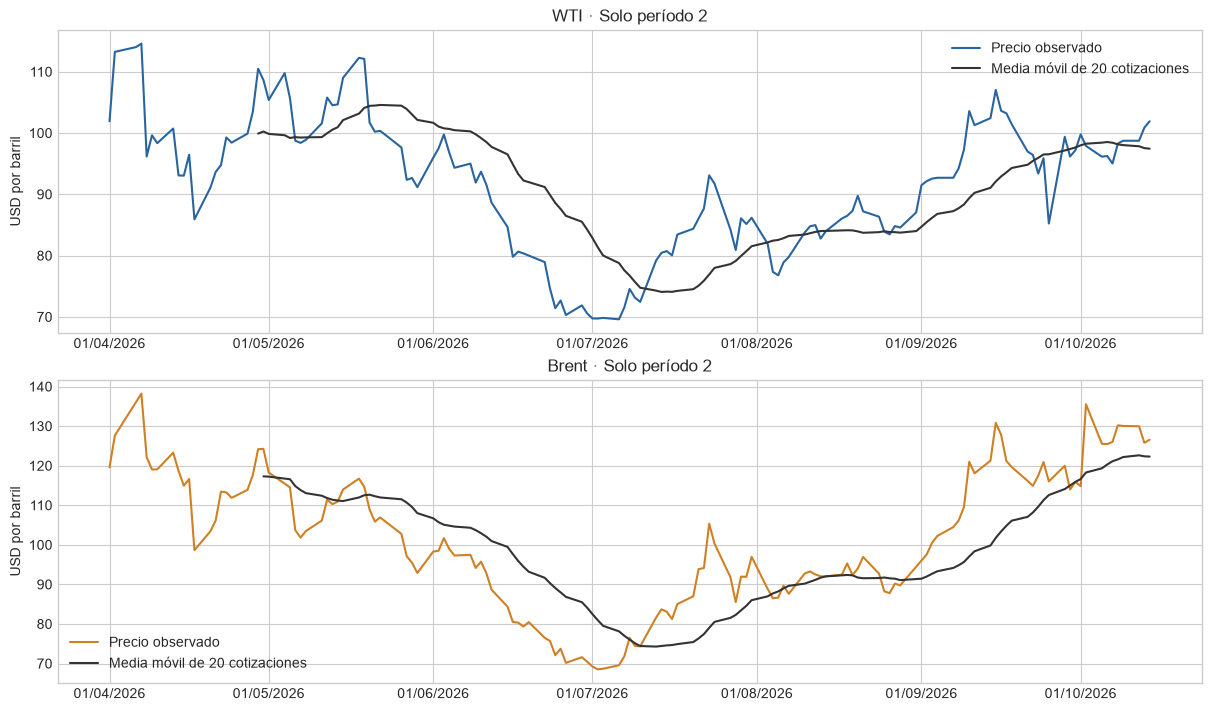

**WTI:** 138 cotizaciones entre 01/04/2026 y 14/10/2026; cambio entre extremos: **+0.01 USD/barril**. Llegar al viernes objetivo requiere **17 pasos**. El cambio entre extremos no implica una tendencia constante durante todo el período.

**Fuente atrasada para WTI:** el último dato tiene más de siete días de demora. El pronóstico parte de ese precio y no conoce los movimientos posteriores; actualizar la fuente reduce la distancia hasta la semana objetivo.

**Brent:** 136 cotizaciones entre 01/04/2026 y 14/10/2026; cambio entre extremos: **+6.99 USD/barril**. Llegar al viernes objetivo requiere **17 pasos**. El cambio entre extremos no implica una tendencia constante durante todo el período.

**Fuente atrasada para Brent:** el último dato tiene más de siete días de demora. El pronóstico parte de ese precio y no conoce los movimientos posteriores; actualizar la fuente reduce la distancia hasta la semana objetivo.

In [5]:
series_periodo_2, fechas_futuras, horizontes = {}, {}, {}
filas_cobertura = []
for crudo, codigo in {"WTI": "RWTC", "Brent": "RBRTE"}.items():
    muestra = df_periodo_2_limpio.loc[df_periodo_2_limpio["series"].eq(codigo)]
    serie = muestra.set_index("period")["value"].sort_index().astype(float).rename(crudo)
    if len(serie) < MIN_OBSERVACIONES:
        raise ValueError(f"{crudo}: se necesitan al menos {MIN_OBSERVACIONES} cotizaciones.")
    if serie.index.max() >= inicio_semana or serie.index.min() < INICIO_PERIODO_2:
        raise ValueError("El entrenamiento contiene fechas fuera del período permitido.")
    futuro = pd.bdate_range(serie.index[-1] + pd.Timedelta(days=1), fin_semana)
    if not fechas_objetivo.isin(futuro).all():
        raise ValueError("El horizonte no contiene toda la semana objetivo.")
    series_periodo_2[crudo], fechas_futuras[crudo] = serie, futuro
    horizontes[crudo] = len(futuro)
    filas_cobertura.append({
        "Crudo": crudo, "Primera cotización": serie.index[0].date(),
        "Última cotización": serie.index[-1].date(), "n": len(serie),
        "Demora al corte (días)": (fecha_referencia - serie.index[-1]).days,
        "Pasos totales": len(futuro), "Pasos previos a semana objetivo": len(futuro) - 5,
    })
display(pd.DataFrame(filas_cobertura))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
for ax, (crudo, serie) in zip(axes, series_periodo_2.items()):
    ax.plot(serie.index, serie, color=COLORES[crudo], label="Precio observado")
    ax.plot(serie.index, serie.rolling(20).mean(), color="#333333", label="Media móvil de 20 cotizaciones")
    ax.set(title=f"{crudo} · Solo período 2", ylabel="USD por barril")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
    ax.legend()
plt.show()
for crudo, serie in series_periodo_2.items():
    cambio = serie.iloc[-1] - serie.iloc[0]
    display(Markdown(
        f"**{crudo}:** {len(serie)} cotizaciones entre {serie.index[0]:%d/%m/%Y} y "
        f"{serie.index[-1]:%d/%m/%Y}; cambio entre extremos: **{cambio:+.2f} USD/barril**. "
        f"Llegar al viernes objetivo requiere **{horizontes[crudo]} pasos**. "
        "El cambio entre extremos no implica una tendencia constante durante todo el período."
    ))
    if (fecha_referencia - serie.index[-1]).days > 7:
        display(Markdown(
            f"**Fuente atrasada para {crudo}:** el último dato tiene más de siete días de demora. "
            "El pronóstico parte de ese precio y no conoce los movimientos posteriores; "
            "actualizar la fuente reduce la distancia hasta la semana objetivo."
        ))

## 5. Modelo ARIMA: identificación y selección

ARIMA combina tres elementos: **p**, cantidad de rezagos autorregresivos; **d**, número de diferencias para estabilizar el nivel; y **q**, cantidad de rezagos de errores. Si \(z_t=\Delta^d y_t\), la forma no estacional puede escribirse como:

\[
z_t=c+\phi_1z_{t-1}+\cdots+\phi_pz_{t-p}
       +\varepsilon_t+\theta_1\varepsilon_{t-1}+\cdots+\theta_q\varepsilon_{t-q}.
\]

La primera diferencia es \(y_t-y_{t-1}\), medida en USD por barril entre cotizaciones consecutivas. **No es un retorno porcentual.** Se entregan a statsmodels los precios originales y el orden `d`: la biblioteca aplica la diferenciación y devuelve pronósticos en precios; no se diferencia dos veces por error.

Se usa **ARIMA no estacional**, sin variables externas. La muestra corta no justifica imponer una estacionalidad semanal o anual sin evidencia. La ACF y la PACF ayudan a describir dependencia temporal, pero no determinan por sí solas el orden.

### 5.1. Estacionariedad: ADF y KPSS

Se aplican ambas pruebas con constante y significancia del 5 %, usando **solo el entrenamiento de cada ajuste**:

- **ADF:** su hipótesis nula es raíz unitaria; un valor p menor a 0,05 aporta evidencia contra esa hipótesis.
- **KPSS:** su hipótesis nula es estacionariedad alrededor de una constante; un valor p menor a 0,05 aporta evidencia contra esa estacionariedad.

Se elige el **menor d entre 0, 1 y 2 para el que KPSS no rechaza estacionariedad**. ADF actúa como diagnóstico complementario; si no coincide se indica que la lectura es no concluyente. No rechazar una hipótesis no la demuestra. Si KPSS rechaza incluso con dos diferencias, el ajuste se detiene para revisar la serie. KPSS limita sus valores p tabulados: se muestran `≤ 0,01` o `≥ 0,10` cuando corresponde.

La regla limita la diferenciación para evitar añadir complejidad innecesaria. Los cambios de régimen, la volatilidad y el tamaño muestral pueden afectar estas pruebas. [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html) · [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html).

Los valores p cercanos a 0,05 pueden cambiar la elección de d al sumar observaciones. Se muestran seis decimales para KPSS cuando el valor no está limitado, y las decisiones utilizan toda la precisión disponible.

In [6]:
def diagnosticar_y_elegir_d(serie):
    """Elegir diferenciación con el prefijo de entrenamiento, sin mirar el test."""
    valores = np.asarray(serie, dtype=float)
    filas = []
    opciones_adf = {"result_object": True} if "result_object" in signature(adfuller).parameters else {}
    opciones_kpss = {"result_object": True} if "result_object" in signature(kpss).parameters else {}
    for d in range(MAX_D + 1):
        z = np.diff(valores, n=d)
        if len(z) < 20 or np.ptp(z) < 1e-10:
            raise ValueError("Las pruebas requieren al menos 20 observaciones no constantes.")
        adf = adfuller(z, regression="c", autolag="AIC", **opciones_adf)
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always", InterpolationWarning)
            kp = kpss(z, regression="c", nlags="auto", **opciones_kpss)
        if hasattr(adf, "statistic"):
            estad_adf, p_adf, lag_adf = float(adf.statistic), float(adf.pvalue), int(adf.lags)
        else:
            estad_adf, p_adf, lag_adf = float(adf[0]), float(adf[1]), int(adf[2])
        if hasattr(kp, "statistic"):
            estad_kp, p_kp, lag_kp = float(kp.statistic), float(kp.pvalue), int(kp.lags)
        else:
            estad_kp, p_kp, lag_kp = float(kp[0]), float(kp[1]), int(kp[2])
        limitado = any(issubclass(a.category, InterpolationWarning) for a in avisos)
        p_texto = f"{p_kp:.6f}"
        if limitado and np.isclose(p_kp, 0.01):
            p_texto = "≤ 0.01"
        elif limitado and np.isclose(p_kp, 0.10):
            p_texto = "≥ 0.10"
        acepta_kp = p_kp >= SIGNIFICANCIA
        lectura = ("Compatible con estacionariedad" if p_adf < SIGNIFICANCIA else
                   "No concluyente: ADF no rechaza raíz unitaria") if acepta_kp else (
                   "KPSS rechaza estacionariedad; probar otra diferencia")
        filas.append({
            "d": d, "n": len(z), "ADF": estad_adf, "p ADF": p_adf,
            "Rezagos ADF": lag_adf, "KPSS": estad_kp, "p KPSS mostrado": p_texto,
            "Rezagos KPSS": lag_kp, "KPSS no rechaza": acepta_kp, "Lectura": lectura,
        })
        if acepta_kp:
            return d, pd.DataFrame(filas)
    raise ValueError("KPSS rechaza estacionariedad hasta d=2; revisar cambios de régimen antes de continuar.")

### 5.2. Selección de p, q y término determinista con AICc

Con `d` ya fijado, se exploran `p` y `q` de 0 a 2 con `p + q ≤ 3`. Se elige el **menor AICc entre ajustes convergidos y finitos**. AICc equilibra ajuste y complejidad con una corrección por tamaño muestral: **no es un error de pronóstico ni se expresa en USD**. Se comparan solo modelos del mismo crudo, entrenamiento y `d`; nunca se elige `d` comparando AICc.

- Con `d = 0`: se prueba sin constante (`n`) y con constante (`c`). En esta implementación, `const` representa la media del nivel estacionario.
- Con `d = 1`: se prueba sin deriva (`n`) y con deriva (`t`). `t` es una tendencia lineal en precios, equivalente a una media no nula de las diferencias.
- Con `d = 2`: se usa `n`, sin término determinista.

Todos se estiman por máxima verosimilitud mediante espacio de estados, imponiendo estacionariedad a la parte AR e invertibilidad a la parte MA. Las advertencias se guardan en la tabla de candidatos; los ajustes fallidos quedan marcados como descartados. Si ninguno es válido, se detiene el análisis. El procedimiento es el mismo para ambos crudos y se repite dentro de cada corte de validación.

Un ARIMA(0,1,0) sin deriva puede resultar elegido: su pronóstico puntual coincide con repetir el último precio. Esa selección es un resultado válido. [ARIMA en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html) · [Selección y estimación de ARIMA](https://otexts.com/fpp3/arima.html#estimation-and-order-selection).

In [7]:
def seleccionar_arima(serie):
    """Seleccionar d por KPSS y luego p/q/tendencia por AICc solo en entrenamiento."""
    valores = np.asarray(serie, dtype=float)
    if len(valores) < MIN_OBSERVACIONES or not np.isfinite(valores).all():
        raise ValueError(f"Se requieren {MIN_OBSERVACIONES} precios finitos de entrenamiento.")
    if isinstance(serie, pd.Series) and isinstance(serie.index, pd.DatetimeIndex):
        if serie.index.min() < INICIO_PERIODO_2 or not serie.index.is_monotonic_increasing:
            raise ValueError("El entrenamiento debe estar ordenado y pertenecer al período 2.")
    d, diagnostico = diagnosticar_y_elegir_d(valores)
    tendencias = {0: ["n", "c"], 1: ["n", "t"], 2: ["n"]}[d]
    registros, mejor = [], None
    for p, q in product(range(MAX_P + 1), range(MAX_Q + 1)):
        if p + q > MAX_P_MAS_Q:
            continue
        for tendencia in tendencias:
            fila = {"Orden": f"({p},{d},{q})", "Término": tendencia,
                    "AICc": np.nan, "Estado": "Descartado", "Avisos": ""}
            try:
                with warnings.catch_warnings(record=True) as avisos:
                    warnings.simplefilter("always")
                    ajuste = ARIMA(
                        valores, order=(p, d, q), trend=tendencia,
                        enforce_stationarity=True, enforce_invertibility=True,
                    ).fit(method="statespace", method_kwargs={"maxiter": 300})
                fila["Avisos"] = " | ".join(dict.fromkeys(str(a.message) for a in avisos))
                if not ajuste.mle_retvals.get("converged", False):
                    raise RuntimeError("No convergió.")
                if not np.isfinite(ajuste.aicc) or not np.isfinite(ajuste.params).all():
                    raise RuntimeError("AICc o parámetros no finitos.")
                fila.update({"AICc": float(ajuste.aicc), "Estado": "Válido"})
                if mejor is None or ajuste.aicc < mejor["ajuste"].aicc:
                    mejor = {"ajuste": ajuste, "orden": (p, d, q), "tendencia": tendencia}
            except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as error:
                fila["Avisos"] = (fila["Avisos"] + " | " + str(error)).strip(" |")
            registros.append(fila)
    if mejor is None:
        raise RuntimeError("Ningún ARIMA candidato convergió con resultados finitos.")
    mejor["diagnostico"] = diagnostico
    mejor["candidatos"] = pd.DataFrame(registros).sort_values("AICc", na_position="last")
    return mejor


def predecir_arima(caso, fechas):
    """Pronosticar todos los pasos, conservando precios en USD/barril."""
    if len(fechas) == 0:
        raise ValueError("El horizonte debe contener al menos un paso.")
    prediccion = caso["ajuste"].get_forecast(steps=len(fechas))
    media = np.asarray(prediccion.predicted_mean, dtype=float)
    limites = np.asarray(prediccion.conf_int(alpha=ALFA_INTERVALO), dtype=float)
    if not np.isfinite(media).all() or not np.isfinite(limites).all():
        raise RuntimeError("El pronóstico o sus intervalos contienen valores no finitos.")
    ultimo = float(np.asarray(caso["ajuste"].model.endog).ravel()[-1])
    return pd.DataFrame({"ARIMA": media, "Inferior95": limites[:, 0],
                         "Superior95": limites[:, 1], "Ultimo_precio": ultimo}, index=fechas)


def calcular_metricas(real, predicho):
    """Errores fuera del entrenamiento, expresados en USD por barril."""
    error = np.asarray(real, dtype=float) - np.asarray(predicho, dtype=float)
    if error.size == 0 or not np.isfinite(error).all():
        raise ValueError("La evaluación necesita observaciones reales y predicciones finitas.")
    return {"MAE (USD/barril)": float(np.mean(np.abs(error))),
            "RMSE (USD/barril)": float(np.sqrt(np.mean(error ** 2)))}

### 5.3. Diagnóstico inicial sin utilizar los precios reservados

Los gráficos y las pruebas siguientes se calculan sobre el **entrenamiento del primer corte de validación**. Así, las observaciones que después se evalúan todavía no participan de la identificación inicial. La selección de cada corte vuelve a calcularse con su propio pasado.

En la ACF se mide correlación con cada rezago; la PACF aísla la asociación con ese rezago controlando los anteriores. Las bandas son referencias aproximadas del 95 %: algún punto aislado fuera de ellas puede aparecer por azar. No se exige que todos los rezagos de la serie diferenciada sean cero: la dependencia restante es justamente la que pueden modelar AR y MA.

**WTI:** diagnóstico con 111 precios hasta 07/09/2026. Se elige **d = 1**.

,d,n,ADF,p ADF,Rezagos ADF,KPSS,p KPSS mostrado,Rezagos KPSS,KPSS no rechaza,Lectura
0,0,111,-2.339964,1.594024e-01,1,0.883549,≤ 0.01,6,False,KPSS rechaza estacionariedad; probar otra dife...
1,1,110,-7.858531,5.361233e-12,1,0.101262,≥ 0.10,2,True,Compatible con estacionariedad


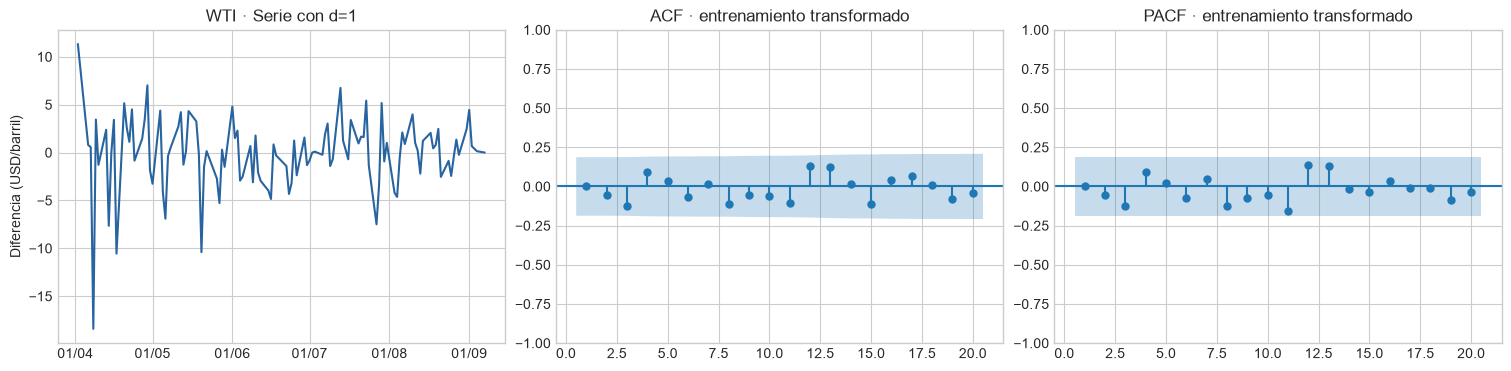

**Lectura de WTI:** Compatible con estacionariedad. Los rezagos cuentan cotizaciones, con posibles huecos de calendario.

**Brent:** diagnóstico con 109 precios hasta 07/09/2026. Se elige **d = 1**.

,d,n,ADF,p ADF,Rezagos ADF,KPSS,p KPSS mostrado,Rezagos KPSS,KPSS no rechaza,Lectura
0,0,109,-1.812400,3.743232e-01,3,0.881047,≤ 0.01,6,False,KPSS rechaza estacionariedad; probar otra dife...
1,1,108,-6.976824,8.387038e-10,2,0.190620,≥ 0.10,0,True,Compatible con estacionariedad


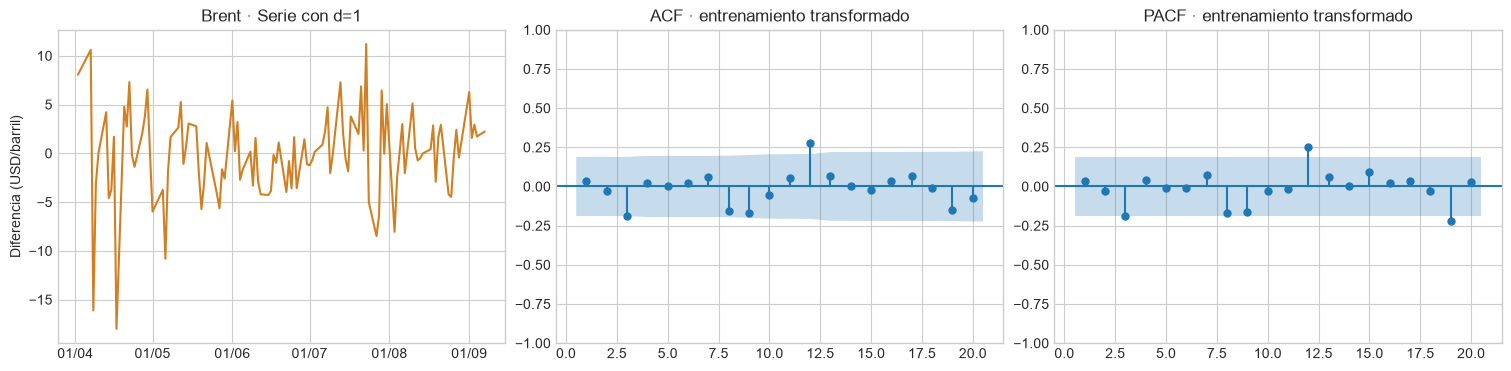

**Lectura de Brent:** Compatible con estacionariedad. Los rezagos cuentan cotizaciones, con posibles huecos de calendario.

In [8]:
diagnosticos_iniciales = {}
for crudo, serie in series_periodo_2.items():
    primer_origen = len(serie) - horizontes[crudo] - (N_ORIGENES_VALIDACION - 1) * 5
    if primer_origen < MIN_OBSERVACIONES:
        raise ValueError(f"{crudo}: faltan datos para validar el horizonte actual; actualizar la fuente o revisar el corte.")
    entrenamiento_inicial = serie.iloc[:primer_origen]
    d, diagnostico = diagnosticar_y_elegir_d(entrenamiento_inicial)
    diagnosticos_iniciales[crudo] = diagnostico
    display(Markdown(
        f"**{crudo}:** diagnóstico con {len(entrenamiento_inicial)} precios hasta "
        f"{entrenamiento_inicial.index[-1]:%d/%m/%Y}. Se elige **d = {d}**."
    ))
    display(diagnostico)
    z = np.diff(entrenamiento_inicial.to_numpy(), n=d)
    rezagos = min(20, len(z) // 2 - 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
    axes[0].plot(entrenamiento_inicial.index[d:], z, color=COLORES[crudo])
    axes[0].set(title=f"{crudo} · Serie con d={d}", ylabel="USD/barril" if d == 0 else "Diferencia (USD/barril)")
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    plot_acf(z, lags=rezagos, zero=False, ax=axes[1], title="ACF · entrenamiento transformado")
    plot_pacf(z, lags=rezagos, zero=False, method="ywm", ax=axes[2], title="PACF · entrenamiento transformado")
    plt.show()
    display(Markdown(f"**Lectura de {crudo}:** {diagnostico.iloc[-1]['Lectura']}. "
                     "Los rezagos cuentan cotizaciones, con posibles huecos de calendario."))

## 6. Validación temporal frente al último precio

Se utilizan **tres orígenes de entrenamiento que avanzan cinco cotizaciones**. En cada uno se eligen `d`, `p`, `q` y el término determinista utilizando exclusivamente los precios anteriores al corte; después se pronostica sin incorporar los valores reservados.

El horizonte total replica el número de pasos necesario hoy para llegar al viernes objetivo. Se evalúan sus **últimos cinco pasos**, de modo que también se respeta la distancia previa a la semana pronosticada. Las tres ventanas evaluadas no se superponen. Los cortes son por cotizaciones: no necesariamente corresponden a semanas calendario de lunes a viernes.

La referencia ingenua repite el último precio disponible al cortar. **MAE** es el error absoluto promedio y **RMSE** penaliza más los errores grandes; ambos se expresan en USD por barril y cuanto menores, mejor. Se muestran los errores por corte y los errores conjuntos sobre 15 cotizaciones por crudo. Una evaluación tan corta es evidencia local, no una garantía futura. Este resultado no se usa para cambiar manualmente la búsqueda y favorecer a ARIMA.

Referencia: [validación temporal de pronósticos](https://otexts.com/fpp3/toolbox.html#time-series-cross-validation).

In [9]:
filas_ventanas, filas_errores = [], []
ultimas_validaciones = {}
selecciones_validacion = {}
for crudo, serie in series_periodo_2.items():
    h = horizontes[crudo]
    primer_origen = len(serie) - h - (N_ORIGENES_VALIDACION - 1) * 5
    if primer_origen < MIN_OBSERVACIONES:
        raise ValueError(f"{crudo}: entrenamiento insuficiente para validar {h} pasos.")
    for numero in range(N_ORIGENES_VALIDACION):
        pos = primer_origen + numero * 5
        entrenamiento = serie.iloc[:pos]
        observado = serie.iloc[pos:pos + h]
        caso = seleccionar_arima(entrenamiento)
        pred = predecir_arima(caso, observado.index)
        evaluado = observado.iloc[-5:]
        selecciones_validacion[(crudo, numero + 1)] = caso
        filas_ventanas.append({
            "Crudo": crudo, "Corte": numero + 1, "n entrenamiento": len(entrenamiento),
            "Último dato entrenado": entrenamiento.index[-1].date(),
            "Evaluación desde": evaluado.index[0].date(),
            "Evaluación hasta": evaluado.index[-1].date(), "Pasos totales": h,
            "Pasos evaluados": 5, "Orden ARIMA": str(caso["orden"]),
            "Término": caso["tendencia"],
        })
        for modelo, columna in [("ARIMA", "ARIMA"), ("Último precio", "Ultimo_precio")]:
            for fecha, real in evaluado.items():
                filas_errores.append({
                    "Crudo": crudo, "Corte": numero + 1, "Modelo": modelo,
                    "Fecha": fecha, "Real": real, "Predicho": pred.loc[fecha, columna],
                })
        ultimas_validaciones[crudo] = {"entrenamiento": entrenamiento,
                                     "observado": observado, "predicciones": pred}

ventanas_validacion = pd.DataFrame(filas_ventanas)
predicciones_validacion = pd.DataFrame(filas_errores)
predicciones_validacion["Error absoluto"] = (
    predicciones_validacion["Real"] - predicciones_validacion["Predicho"]
).abs()
metricas_por_corte = pd.DataFrame([
    {"Crudo": crudo, "Corte": corte, "Modelo": modelo,
     **calcular_metricas(grupo["Real"], grupo["Predicho"])}
    for (crudo, corte, modelo), grupo in predicciones_validacion.groupby(["Crudo", "Corte", "Modelo"], sort=False)
])
metricas_validacion = pd.DataFrame([
    {"Crudo": crudo, "Modelo": modelo, "Casos evaluados": len(grupo),
     **calcular_metricas(grupo["Real"], grupo["Predicho"])}
    for (crudo, modelo), grupo in predicciones_validacion.groupby(["Crudo", "Modelo"], sort=False)
])
display(ventanas_validacion)
display(metricas_por_corte.round(4))
display(metricas_validacion.round(4))

,Crudo,Corte,n entrenamiento,Último dato entrenado,Evaluación desde,Evaluación hasta,Pasos totales,Pasos evaluados,Orden ARIMA,Término
0,WTI,1,111,2026-09-07,2026-09-24,2026-09-30,17,5,"(0, 1, 0)",n
1,WTI,2,116,2026-09-14,2026-10-01,2026-10-07,17,5,"(0, 1, 0)",n
2,WTI,3,121,2026-09-21,2026-10-08,2026-10-14,17,5,"(0, 1, 0)",n
3,Brent,1,109,2026-09-07,2026-09-24,2026-09-30,17,5,"(0, 1, 0)",n
4,Brent,2,114,2026-09-14,2026-10-01,2026-10-07,17,5,"(0, 1, 0)",n
5,Brent,3,119,2026-09-21,2026-10-08,2026-10-14,17,5,"(0, 1, 0)",n


,Crudo,Corte,Modelo,MAE (USD/barril),RMSE (USD/barril)
0,WTI,1,ARIMA,5.058,5.3414
1,WTI,1,Último precio,5.058,5.3414
2,WTI,2,ARIMA,5.410,5.6579
3,WTI,2,Último precio,5.410,5.6579
4,WTI,3,ARIMA,2.728,3.0788
5,WTI,3,Último precio,2.728,3.0788
6,Brent,1,ARIMA,12.884,13.1526
7,Brent,1,Último precio,12.884,13.1526
8,Brent,2,ARIMA,6.778,7.7841
9,Brent,2,Último precio,6.778,7.7841


,Crudo,Modelo,Casos evaluados,MAE (USD/barril),RMSE (USD/barril)
0,WTI,ARIMA,15,4.3987,4.8312
1,WTI,Último precio,15,4.3987,4.8312
2,Brent,ARIMA,15,10.6700,11.3981
3,Brent,Último precio,15,10.6700,11.3981


### 6.1. Gráficos y lectura de la última ventana

La curva ARIMA y la referencia se calculan una sola vez al inicio de cada recorrido. Las cotizaciones reales posteriores se dibujan para evaluar y no se usan para actualizar esas predicciones. La zona sombreada contiene las cinco observaciones que aportan al error del último corte; las anteriores respetan la separación hasta el objetivo.

La comparación numérica se calcula con los tres cortes. Si ARIMA no mejora el MAE del último precio, debe informarse así. No se puede concluir que un método sea superior en toda circunstancia a partir de estas ventanas.

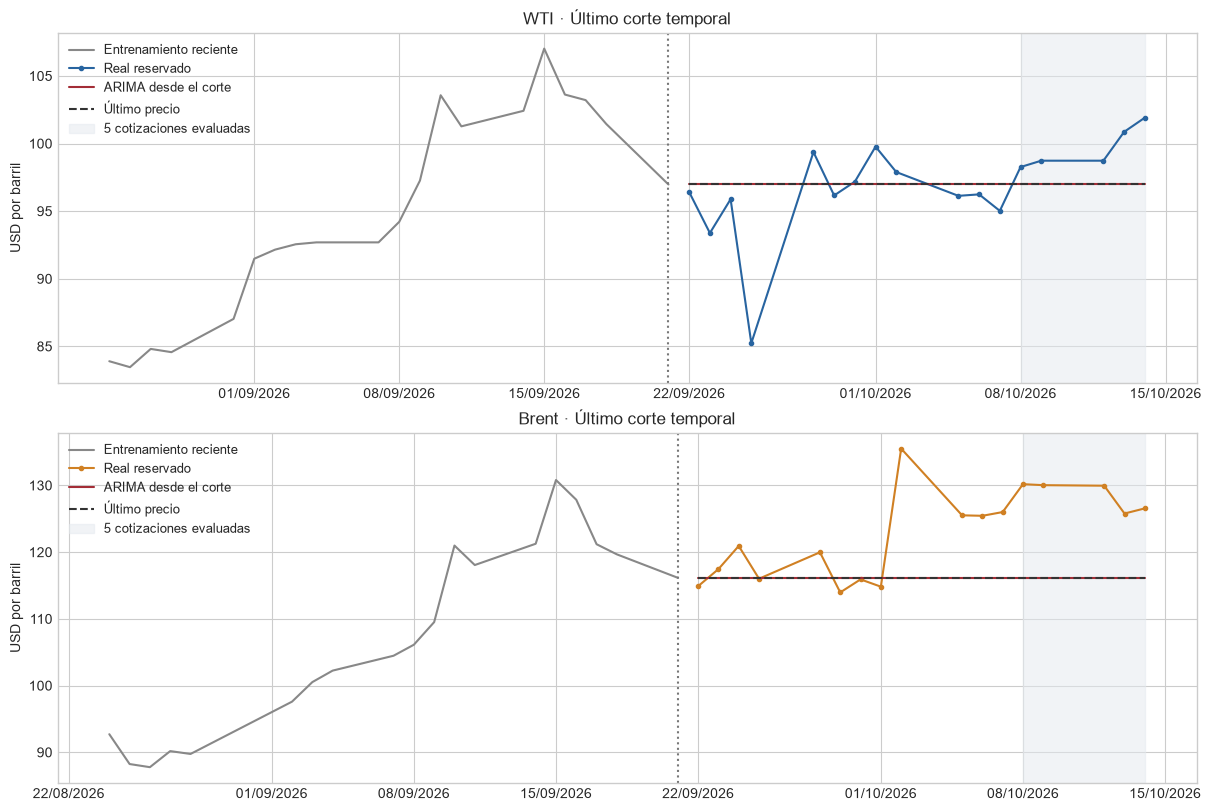

**WTI:** sobre 15 cotizaciones, ARIMA obtuvo **MAE = 4.3987** y **RMSE = 4.8312 USD/barril**. El último precio obtuvo **MAE = 4.3987 USD/barril**. ARIMA **empata prácticamente con** la referencia en estos cortes.

**Brent:** sobre 15 cotizaciones, ARIMA obtuvo **MAE = 10.6700** y **RMSE = 11.3981 USD/barril**. El último precio obtuvo **MAE = 10.6700 USD/barril**. ARIMA **empata prácticamente con** la referencia en estos cortes.

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
for ax, (crudo, caso) in zip(axes, ultimas_validaciones.items()):
    entrenamiento, observado, pred = caso["entrenamiento"], caso["observado"], caso["predicciones"]
    ax.plot(entrenamiento.index[-20:], entrenamiento.iloc[-20:], color="#888888", label="Entrenamiento reciente")
    ax.plot(observado.index, observado, color=COLORES[crudo], marker="o", markersize=3, label="Real reservado")
    ax.plot(pred.index, pred["ARIMA"], color="#A32D36", label="ARIMA desde el corte")
    ax.plot(pred.index, pred["Ultimo_precio"], color="#333333", linestyle="--", label="Último precio")
    ax.axvspan(observado.index[-5], observado.index[-1], color="#E4E9EF", alpha=0.5, label="5 cotizaciones evaluadas")
    ax.axvline(entrenamiento.index[-1], color="#777777", linestyle=":")
    ax.set(title=f"{crudo} · Último corte temporal", ylabel="USD por barril")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
    ax.legend(fontsize=9)
plt.show()

for crudo in series_periodo_2:
    tabla = metricas_validacion.loc[metricas_validacion["Crudo"].eq(crudo)].set_index("Modelo")
    mae_a, mae_b = tabla.loc["ARIMA", "MAE (USD/barril)"], tabla.loc["Último precio", "MAE (USD/barril)"]
    lectura = "empata prácticamente con" if np.isclose(mae_a, mae_b) else (
        "tiene menor MAE que" if mae_a < mae_b else "tiene mayor MAE que")
    display(Markdown(
        f"**{crudo}:** sobre {int(tabla.loc['ARIMA', 'Casos evaluados'])} cotizaciones, "
        f"ARIMA obtuvo **MAE = {mae_a:.4f}** y "
        f"**RMSE = {tabla.loc['ARIMA', 'RMSE (USD/barril)']:.4f} USD/barril**. "
        f"El último precio obtuvo **MAE = {mae_b:.4f} USD/barril**. "
        f"ARIMA **{lectura}** la referencia en estos cortes."
    ))

## 7. Ajuste final y pronóstico de la próxima semana

Después de la evaluación, se vuelve a seleccionar y ajustar ARIMA con **todos los precios válidos del período 2 hasta el corte**. Su orden puede diferir de los órdenes de validación porque dispone de más información. Las tablas muestran las pruebas, todos los candidatos y los coeficientes finales; las advertencias de estimación permanecen visibles.

Los coeficientes `ar.Lk` vinculan el valor transformado con su rezago k; `ma.Lk`, con errores anteriores; `sigma2` representa la varianza estimada de las innovaciones. `const` es la media en nivel si d=0 y `x1` es la deriva cuando d=1 con `t`. Sus intervalos describen la incertidumbre dentro del modelo elegido; no miden la precisión de la semana futura.

Se obtienen **intervalos de predicción condicionales del 95 %**, calculados por statsmodels para observaciones futuras. Dependen de los supuestos del ARIMA y no incorporan toda la incertidumbre de estimación, de elección del modelo o de nuevos acontecimientos. No tienen cobertura empírica garantizada. Los límites no se recortan artificialmente y las tablas se redondean solo para mostrar.

Implementación: [get_forecast](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.get_forecast.html).

Si el diagnóstico final de ADF y KPSS resulta no concluyente, el pronóstico sigue la regla KPSS declarada, pero su elección de diferenciación debe interpretarse con cautela. No se cambia el criterio después de observar los resultados.

In [11]:
ajustes_finales, pronosticos_completos = {}, {}
filas_parametros, filas_semana, filas_modelos = [], [], []
for crudo, serie in series_periodo_2.items():
    caso = seleccionar_arima(serie)
    ajustes_finales[crudo] = caso
    ajuste = caso["ajuste"]
    pred = predecir_arima(caso, fechas_futuras[crudo])
    pronosticos_completos[crudo] = pred
    filas_modelos.append({"Crudo": crudo, "Orden": str(caso["orden"]),
                         "Término": caso["tendencia"], "n": len(serie),
                         "AICc (solo selección)": float(ajuste.aicc)})
    display(Markdown(f"### {crudo} · Selección final"))
    display(caso["diagnostico"])
    display(caso["candidatos"].reset_index(drop=True))
    ci = np.asarray(ajuste.conf_int(alpha=0.05))
    for nombre, valor, error_std, limites in zip(ajuste.param_names, ajuste.params, ajuste.bse, ci):
        filas_parametros.append({"Crudo": crudo, "Parámetro": nombre, "Estimación": valor,
                                "Error estándar": error_std, "Inferior95": limites[0], "Superior95": limites[1]})
    for fecha in fechas_objetivo:
        filas_semana.append({"Crudo": crudo, "Fecha": fecha,
                            "Paso desde último dato": int(pred.index.get_loc(fecha)) + 1,
                            **pred.loc[fecha].to_dict()})

modelos_finales = pd.DataFrame(filas_modelos)
parametros_finales = pd.DataFrame(filas_parametros)
pronostico_semana = pd.DataFrame(filas_semana)
display(modelos_finales.round(4))
display(parametros_finales.round(5))
display(pronostico_semana.round(2))

### WTI · Selección final

,d,n,ADF,p ADF,Rezagos ADF,KPSS,p KPSS mostrado,Rezagos KPSS,KPSS no rechaza,Lectura
0,0,138,-2.098758,0.245014,0,0.46015,0.051228,6,True,No concluyente: ADF no rechaza raíz unitaria


,Orden,Término,AICc,Estado,Avisos
0,"(1,0,0)",c,769.251210,Válido,
1,"(2,0,0)",c,770.563855,Válido,
2,"(1,0,1)",c,770.621447,Válido,
3,"(2,0,1)",c,772.208803,Válido,
4,"(1,0,2)",c,772.639741,Válido,
5,"(1,0,0)",n,776.243267,Válido,
6,"(2,0,0)",n,776.738939,Válido,
7,"(1,0,1)",n,776.751398,Válido,
8,"(2,0,1)",n,778.608640,Válido,
9,"(1,0,2)",n,778.872510,Válido,


### Brent · Selección final

,d,n,ADF,p ADF,Rezagos ADF,KPSS,p KPSS mostrado,Rezagos KPSS,KPSS no rechaza,Lectura
0,0,136,-1.488293,5.392947e-01,0,0.463025,0.049994,6,False,KPSS rechaza estacionariedad; probar otra dife...
1,1,135,-12.243041,9.925284e-23,0,0.255357,≥ 0.10,1,True,Compatible con estacionariedad


,Orden,Término,AICc,Estado,Avisos
0,"(0,1,0)",n,812.367697,Válido,
1,"(1,1,1)",n,812.709910,Válido,
2,"(0,1,1)",n,814.030321,Válido,
3,"(1,1,0)",n,814.038392,Válido,
4,"(0,1,0)",t,814.413246,Válido,
5,"(1,1,1)",t,814.822121,Válido,
6,"(1,1,2)",n,814.823752,Válido,
7,"(0,1,2)",n,816.087166,Válido,
8,"(0,1,1)",t,816.107823,Válido,
9,"(1,1,0)",t,816.115787,Válido,


,Crudo,Orden,Término,n,AICc (solo selección)
0,WTI,"(1, 0, 0)",c,138,769.2512
1,Brent,"(0, 1, 0)",n,136,812.3677


,Crudo,Parámetro,Estimación,Error estándar,Inferior95,Superior95
0,WTI,const,93.46755,4.94708,83.77145,103.16366
1,WTI,ar.L1,0.93601,0.03229,0.87273,0.99929
2,WTI,sigma2,14.53399,1.23471,12.11401,16.95397
3,Brent,sigma2,23.67989,1.76343,20.22362,27.13615


,Crudo,Fecha,Paso desde último dato,ARIMA,Inferior95,Superior95,Ultimo_precio
0,WTI,2026-11-02,13,97.04,77.81,116.27,101.91
1,WTI,2026-11-03,14,96.81,77.32,116.30,101.91
2,WTI,2026-11-04,15,96.60,76.88,116.31,101.91
3,WTI,2026-11-05,16,96.40,76.49,116.31,101.91
4,WTI,2026-11-06,17,96.21,76.13,116.29,101.91
5,Brent,2026-11-02,13,126.55,92.16,160.94,126.55
6,Brent,2026-11-03,14,126.55,90.86,162.24,126.55
7,Brent,2026-11-04,15,126.55,89.61,163.49,126.55
8,Brent,2026-11-05,16,126.55,88.40,164.70,126.55
9,Brent,2026-11-06,17,126.55,87.23,165.87,126.55


### 7.1. Gráficos del pronóstico

La línea histórica representa precios observados. El recorrido punteado muestra los pasos previstos antes de llegar al lunes objetivo; la línea con marcadores contiene la semana solicitada. La banda representa el intervalo de predicción condicional, no un rango observado de precios.

Una trayectoria casi horizontal puede ser coherente con el orden seleccionado y con poca señal predecible en el precio pasado. No significa que el mercado vaya a permanecer inmóvil. Si se dispone de publicaciones más recientes, corresponde actualizar la fuente y ejecutar nuevamente desde el principio.

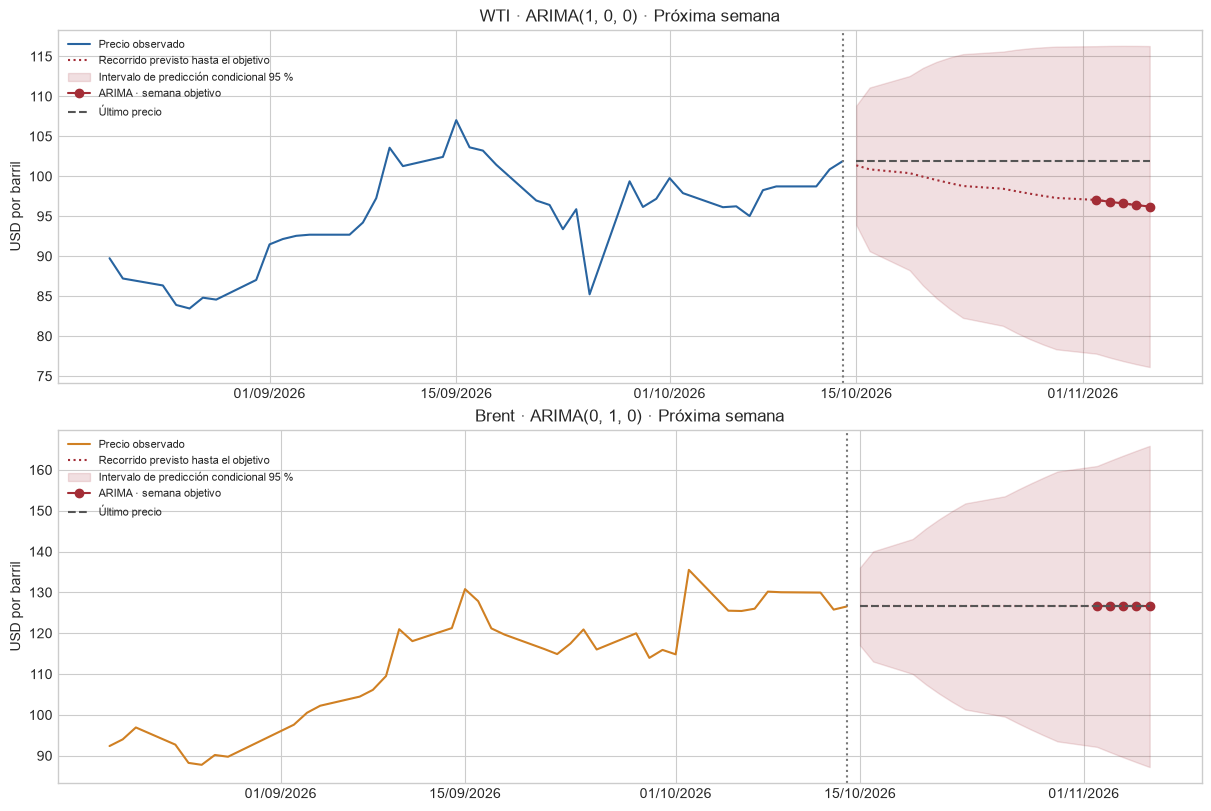

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
for ax, (crudo, serie) in zip(axes, series_periodo_2.items()):
    pred = pronosticos_completos[crudo]
    ax.plot(serie.index[-40:], serie.iloc[-40:], color=COLORES[crudo], label="Precio observado")
    ax.plot(pred.index, pred["ARIMA"], color="#A32D36", linestyle=":", label="Recorrido previsto hasta el objetivo")
    ax.fill_between(pred.index, pred["Inferior95"], pred["Superior95"], color="#A32D36", alpha=0.15,
                    label="Intervalo de predicción condicional 95 %")
    semana = pred.loc[fechas_objetivo]
    ax.plot(semana.index, semana["ARIMA"], color="#A32D36", marker="o", label="ARIMA · semana objetivo")
    ax.plot(pred.index, pred["Ultimo_precio"], color="#555555", linestyle="--", label="Último precio")
    ax.axvline(serie.index[-1], color="#777777", linestyle=":")
    ax.set(title=f"{crudo} · ARIMA{ajustes_finales[crudo]['orden']} · Próxima semana", ylabel="USD por barril")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
    ax.legend(fontsize=8)
plt.show()

## 8. Residuos y límites de la interpretación

Los residuos son errores de predicción de **un paso dentro del entrenamiento**, distintos de los errores reservados del punto 6. Para el diagnóstico se usan innovaciones estandarizadas y se excluye la inicialización difusa del filtro: se descarta el máximo entre el arranque de verosimilitud, las observaciones difusas y `d`.

Se busca una secuencia centrada cerca de cero, sin patrones claros ni autocorrelación remanente. El gráfico Q–Q compara su distribución con una normal: desvíos en las colas sugieren que los extremos no siguen bien ese supuesto. Agrupamientos de amplitud sugieren variaciones de volatilidad que ARIMA no modela explícitamente.

**Ljung–Box** contrasta ausencia conjunta de autocorrelación hasta cada rezago indicado. Se utiliza `model_df=p+q` y solo rezagos mayores que esos grados de libertad. Un valor p menor a 0,05 señala dependencia remanente; no rechazar no demuestra independencia, normalidad ni estabilidad de la varianza. Se informa la lectura de los rezagos evaluados, sin usarla para retocar el modelo después de ver el test.

Referencia: [Ljung–Box en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).

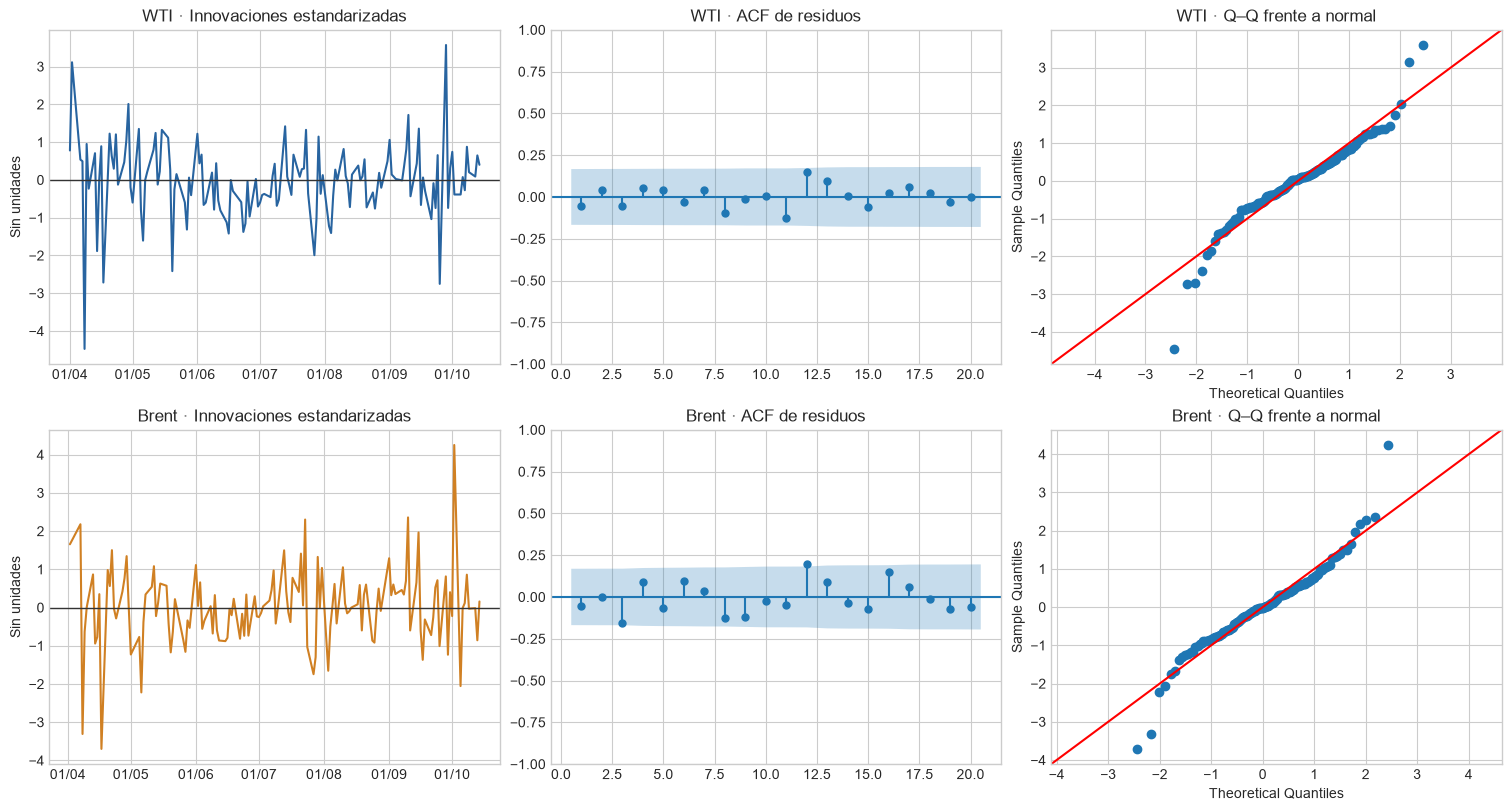

,Crudo,Iniciales excluidos,n residuos,Media estandarizada,Desvío estandarizado
0,WTI,0,138,-0.0254,1.0033
1,Brent,1,135,0.0106,1.0037


,Crudo,Rezago,lb_stat,lb_pvalue
0,WTI,5,1.7826,0.7757
1,WTI,10,3.5032,0.9410
2,WTI,20,11.9839,0.8863
3,Brent,5,5.5134,0.3565
4,Brent,10,11.4637,0.3226
5,Brent,20,25.1779,0.1947


**WTI:** no se rechaza ausencia de autocorrelación en los rezagos evaluados. Esta lectura no demuestra que se cumplan todos los supuestos del modelo.

**Brent:** no se rechaza ausencia de autocorrelación en los rezagos evaluados. Esta lectura no demuestra que se cumplan todos los supuestos del modelo.

**Colas de WTI:** se observan **3 innovaciones** con magnitud mayor a tres desvíos estandarizados. El conteo es descriptivo; junto con los desvíos del gráfico Q–Q ayuda a revisar si la normalidad aproxima bien los extremos.

**Colas de Brent:** se observan **3 innovaciones** con magnitud mayor a tres desvíos estandarizados. El conteo es descriptivo; junto con los desvíos del gráfico Q–Q ayuda a revisar si la normalidad aproxima bien los extremos.

In [13]:
residuos_finales, filas_residuos, tablas_ljung = {}, [], []
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for fila, (crudo, caso) in enumerate(ajustes_finales.items()):
    ajuste = caso["ajuste"]
    p, d, q = caso["orden"]
    burn = max(int(ajuste.loglikelihood_burn), int(getattr(ajuste.filter_results, "nobs_diffuse", 0)), d)
    residuos = np.asarray(ajuste.filter_results.standardized_forecasts_error[0], dtype=float)[burn:]
    fechas = series_periodo_2[crudo].index[burn:]
    validos = np.isfinite(residuos)
    residuos, fechas = residuos[validos], fechas[validos]
    residuos_finales[crudo] = pd.Series(residuos, index=fechas)
    rezagos = [lag for lag in (5, 10, 20) if p + q < lag <= len(residuos) // 5]
    if not rezagos:
        raise ValueError(f"{crudo}: faltan residuos para Ljung–Box.")
    lb = acorr_ljungbox(residuos, lags=rezagos, model_df=p + q, return_df=True)
    # Compatibilidad con resultados tabulares de statsmodels 0.14 y 0.15.
    if not isinstance(lb, pd.DataFrame):
        lb = lb.to_dataframe()
    lb = lb.rename_axis("Rezago").reset_index()
    lb.insert(0, "Crudo", crudo)
    tablas_ljung.append(lb)
    filas_residuos.append({"Crudo": crudo, "Iniciales excluidos": burn, "n residuos": len(residuos),
                          "Media estandarizada": float(np.mean(residuos)),
                          "Desvío estandarizado": float(np.std(residuos, ddof=1))})
    axes[fila, 0].plot(fechas, residuos, color=COLORES[crudo])
    axes[fila, 0].axhline(0, color="#333333", linewidth=1)
    axes[fila, 0].set(title=f"{crudo} · Innovaciones estandarizadas", ylabel="Sin unidades")
    axes[fila, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    plot_acf(residuos, lags=min(20, len(residuos) // 2 - 1), zero=False,
             ax=axes[fila, 1], title=f"{crudo} · ACF de residuos")
    qqplot(residuos, line="45", fit=True, ax=axes[fila, 2])
    axes[fila, 2].set_title(f"{crudo} · Q–Q frente a normal")
plt.show()
diagnostico_residuos = pd.DataFrame(filas_residuos)
ljung_box = pd.concat(tablas_ljung, ignore_index=True)
display(diagnostico_residuos.round(4))
display(ljung_box.round(4))
for crudo in ajustes_finales:
    valores_p = ljung_box.loc[ljung_box["Crudo"].eq(crudo), "lb_pvalue"]
    texto = ("hay evidencia de autocorrelación remanente en al menos un rezago evaluado"
             if valores_p.lt(SIGNIFICANCIA).any() else
             "no se rechaza ausencia de autocorrelación en los rezagos evaluados")
    display(Markdown(f"**{crudo}:** {texto}. "
                     "Esta lectura no demuestra que se cumplan todos los supuestos del modelo."))
for crudo, residuos in residuos_finales.items():
    extremos = int(residuos.abs().gt(3).sum())
    display(Markdown(
        f"**Colas de {crudo}:** se observan **{extremos} innovaciones** con magnitud mayor "
        "a tres desvíos estandarizados. El conteo es descriptivo; junto con los desvíos "
        "del gráfico Q–Q ayuda a revisar si la normalidad aproxima bien los extremos."
    ))


## 9. Lectura para el TP

El resumen siguiente reúne el orden final, la fecha del último precio y la evaluación con datos reservados. La complejidad de ARIMA no asegura una mejora frente al último precio. Los resultados se describen por separado para cada crudo y pueden cambiar al actualizar el corte.

El período 2 se analiza por decisión del diseño del trabajo; este notebook no compara ambos períodos ni prueba que la guerra explique sus diferencias. ARIMA utiliza la estructura temporal de los precios observados y no anticipa decisiones políticas, interrupciones de oferta u otros acontecimientos nuevos.

La validación principal comprende 15 cotizaciones por crudo, con horizontes que se superponen en su recorrido aunque las cinco fechas evaluadas de cada corte sean distintas. Por lo tanto, los errores no son réplicas independientes ni permiten afirmar una probabilidad universal de acierto. El test histórico del punto 10 complementa la lectura con una semana concreta; no es una segunda muestra independiente si coincide con fechas ya evaluadas.

In [14]:
for crudo, caso in ajustes_finales.items():
    serie = series_periodo_2[crudo]
    tabla = metricas_validacion.loc[metricas_validacion["Crudo"].eq(crudo)].set_index("Modelo")
    semana = pronosticos_completos[crudo].loc[fechas_objetivo]
    mae_a, mae_b = tabla.loc["ARIMA", "MAE (USD/barril)"], tabla.loc["Último precio", "MAE (USD/barril)"]
    balance = ("igualó prácticamente" if np.isclose(mae_a, mae_b) else
               "mejoró" if mae_a < mae_b else "no mejoró")
    display(Markdown(
        f"**{crudo}.** El ajuste final es **ARIMA{caso['orden']}**, término **{caso['tendencia']}**, "
        f"con {len(serie)} cotizaciones del período 2. El último precio disponible es "
        f"**{serie.iloc[-1]:.2f} USD/barril del {serie.index[-1]:%d/%m/%Y}**. "
        f"En validación temporal ARIMA obtuvo **MAE {mae_a:.4f} USD/barril** y {balance} "
        f"la referencia, cuyo MAE fue **{mae_b:.4f} USD/barril**. "
        f"Para {inicio_semana:%d/%m/%Y}–{fin_semana:%d/%m/%Y}, los pronósticos puntuales van de "
        f"**{semana['ARIMA'].min():.2f} a {semana['ARIMA'].max():.2f} USD/barril**. "
        "Ese rango resume los cinco pronósticos centrales; la incertidumbre se muestra en las bandas del punto 7."
    ))
display(Markdown(
    "**Conclusión metodológica:** el desempeño comunicado proviene de precios posteriores a cada "
    "entrenamiento y nunca del ajuste dentro de muestra. Las cotizaciones de la semana futura "
    "deberán contrastarse por fecha cuando estén publicadas, conservando el corte y el pronóstico originales."
))

**WTI.** El ajuste final es **ARIMA(1, 0, 0)**, término **c**, con 138 cotizaciones del período 2. El último precio disponible es **101.91 USD/barril del 14/10/2026**. En validación temporal ARIMA obtuvo **MAE 4.3987 USD/barril** y igualó prácticamente la referencia, cuyo MAE fue **4.3987 USD/barril**. Para 02/11/2026–06/11/2026, los pronósticos puntuales van de **96.21 a 97.04 USD/barril**. Ese rango resume los cinco pronósticos centrales; la incertidumbre se muestra en las bandas del punto 7.

**Brent.** El ajuste final es **ARIMA(0, 1, 0)**, término **n**, con 136 cotizaciones del período 2. El último precio disponible es **126.55 USD/barril del 14/10/2026**. En validación temporal ARIMA obtuvo **MAE 10.6700 USD/barril** y igualó prácticamente la referencia, cuyo MAE fue **10.6700 USD/barril**. Para 02/11/2026–06/11/2026, los pronósticos puntuales van de **126.55 a 126.55 USD/barril**. Ese rango resume los cinco pronósticos centrales; la incertidumbre se muestra en las bandas del punto 7.

**Conclusión metodológica:** el desempeño comunicado proviene de precios posteriores a cada entrenamiento y nunca del ajuste dentro de muestra. Las cotizaciones de la semana futura deberán contrastarse por fecha cuando estén publicadas, conservando el corte y el pronóstico originales.

<a id="prueba-historica-semanal-arima"></a>

## 10. Prueba histórica semanal de ARIMA

**Objetivo.** Simular qué se habría pronosticado al cierre del viernes anterior a una semana que ya conocemos y comparar después las predicciones con sus cotizaciones reales. Se ajusta un ARIMA independiente para WTI y Brent, siempre con datos del período 2.

**Cómo ejecutarla.** Ejecutar primero los puntos 1 a 5 de este notebook y luego todas las celdas del punto 10 en orden. Esta sección reutiliza las series limpias y las funciones del modelo. Para probar otra semana, editar solamente `PRUEBA_LUNES_OBJETIVO` en la próxima celda.

El orden ARIMA se vuelve a seleccionar usando únicamente el entrenamiento anterior a la semana elegida. Los precios de esa semana no participan de las pruebas de estacionariedad, de la selección del orden ni del ajuste. Se generan todos los pronósticos de una sola vez, sin actualizar el modelo con las cotizaciones del lunes al viernes.

In [15]:
# CAMBIAR LA SEMANA DE LA PRUEBA: indicar la fecha de un LUNES.
PRUEBA_LUNES_OBJETIVO = "2026-10-05"

prueba_lunes = pd.Timestamp(PRUEBA_LUNES_OBJETIVO).normalize()
prueba_viernes = prueba_lunes + pd.Timedelta(days=4)
prueba_corte = prueba_lunes - pd.Timedelta(days=3)
prueba_fechas = pd.bdate_range(prueba_lunes, prueba_viernes)

display(Markdown(
    f"**Semana elegida:** {prueba_lunes:%d/%m/%Y} al {prueba_viernes:%d/%m/%Y}.  \n"
    f"**Corte de entrenamiento:** {prueba_corte:%d/%m/%Y}, inclusive.  \n"
    f"**Fecha de referencia de esta ejecución:** {fecha_referencia:%d/%m/%Y}."
))

**Semana elegida:** 05/10/2026 al 09/10/2026.  
**Corte de entrenamiento:** 02/10/2026, inclusive.  
**Fecha de referencia de esta ejecución:** 26/10/2026.

### 10.1. Corte temporal y ajuste con el pasado

La función siguiente separa explícitamente el entrenamiento y las cotizaciones reservadas. Entrena desde el inicio del período 2 hasta el viernes anterior, inclusive; el precio real se incorpora a la tabla de evaluación después del ajuste.

Si la última publicación anterior al corte es más antigua que ese viernes, se pronostican también los días intermedios necesarios para llegar a la semana elegida. Un paso representa una cotización; al asignarle una fecha futura se aproxima el calendario con lunes a viernes, tal como en el pronóstico principal.

Se requieren al menos `MIN_OBSERVACIONES` cotizaciones de entrenamiento. Una serie sin datos suficientes o sin precios reales de la semana se informa y se omite. La semana debe haber terminado a la fecha de referencia. Si faltan algunas cotizaciones reales, se conservan las cinco predicciones y la evaluación se marca como **parcial**, sin completar precios ausentes.

In [16]:
def ejecutar_prueba_historica(series, lunes_objetivo, referencia):
    """Entrenar solo con el pasado y evaluar una semana histórica sin actualizar el modelo."""
    lunes = pd.Timestamp(lunes_objetivo).normalize()
    referencia = pd.Timestamp(referencia).normalize()
    viernes = lunes + pd.Timedelta(days=4)
    corte = lunes - pd.Timedelta(days=3)
    fechas = pd.bdate_range(lunes, viernes)
    columnas_detalle = [
        "Crudo", "Fecha", "Real", "ARIMA", "Inferior95", "Superior95",
        "Ultimo_precio", "Error ARIMA", "Error absoluto ARIMA",
        "Error absoluto último precio",
    ]
    detalles, metricas, casos = [], [], {}

    # La prueba se omite ante una configuración que no representa una semana histórica completa.
    if lunes.weekday() != 0:
        display(Markdown("**Prueba omitida:** la fecha elegida debe ser un lunes."))
        return pd.DataFrame(columns=columnas_detalle), pd.DataFrame(), casos
    if lunes < INICIO_PERIODO_2 or viernes > referencia:
        display(Markdown(
            "**Prueba omitida:** elegir una semana del período 2 cuyo viernes "
            "sea anterior o igual a la fecha de referencia."
        ))
        return pd.DataFrame(columns=columnas_detalle), pd.DataFrame(), casos

    for crudo, serie_original in series.items():
        # Recortar otra vez garantiza que ningún precio de otro período llegue al modelo.
        serie = serie_original.sort_index().loc[
            lambda s: (s.index >= INICIO_PERIODO_2) & (s.index <= referencia)
        ]
        entrenamiento = serie.loc[serie.index <= corte].copy()
        reales = serie.reindex(fechas)
        n_reales = int(reales.notna().sum())
        if len(entrenamiento) < MIN_OBSERVACIONES:
            display(Markdown(
                f"**{crudo}: prueba omitida.** Hay {len(entrenamiento)} cotizaciones "
                f"anteriores al corte y se requieren {MIN_OBSERVACIONES}."
            ))
            continue
        if n_reales == 0:
            display(Markdown(
                f"**{crudo}: prueba omitida.** La fuente no contiene cotizaciones "
                "reales de la semana elegida."
            ))
            continue

        # Selección y ajuste reciben únicamente cotizaciones anteriores al corte.
        caso = seleccionar_arima(entrenamiento)
        recorrido = pd.bdate_range(
            entrenamiento.index[-1] + pd.Timedelta(days=1), viernes
        )
        pronostico_completo = predecir_arima(caso, recorrido)
        pronostico_semana = pronostico_completo.reindex(fechas)
        if pronostico_semana[
            ["ARIMA", "Inferior95", "Superior95", "Ultimo_precio"]
        ].isna().any().any():
            raise RuntimeError(f"{crudo}: el pronóstico no cubre las cinco fechas objetivo.")

        # Los reales se utilizan recién aquí, después de seleccionar y ajustar el ARIMA.
        tabla = pronostico_semana.copy()
        tabla.insert(0, "Real", reales.to_numpy(dtype=float))
        tabla.index.name = "Fecha"
        tabla = tabla.reset_index()
        tabla.insert(0, "Crudo", crudo)
        tabla["Error ARIMA"] = tabla["Real"] - tabla["ARIMA"]
        tabla["Error absoluto ARIMA"] = tabla["Error ARIMA"].abs()
        tabla["Error absoluto último precio"] = (
            tabla["Real"] - tabla["Ultimo_precio"]
        ).abs()
        detalles.append(tabla[columnas_detalle])

        # Ambas referencias se evalúan exactamente sobre las mismas fechas observadas.
        evaluables = tabla["Real"].notna()
        estado = "COMPLETA" if n_reales == 5 else "PARCIAL"
        for modelo, columna in [("ARIMA", "ARIMA"), ("Último precio", "Ultimo_precio")]:
            metricas.append({
                "Crudo": crudo, "Modelo": modelo, "Evaluación": estado,
                "Cotizaciones evaluadas": n_reales, "Cotizaciones faltantes": 5 - n_reales,
                **calcular_metricas(
                    tabla.loc[evaluables, "Real"], tabla.loc[evaluables, columna]
                ),
            })
        casos[crudo] = {
            "entrenamiento": entrenamiento, "reales": reales, "caso": caso,
            "pronostico_completo": pronostico_completo, "tabla": tabla,
            "corte": corte, "lunes": lunes, "viernes": viernes,
            "pasos_totales": len(recorrido),
        }
        faltantes = ", ".join(f"{fecha:%d/%m/%Y}" for fecha in fechas[reales.isna()])
        display(Markdown(
            f"**{crudo}: evaluación {estado}.** Orden ARIMA {caso['orden']}; "
            f"{len(entrenamiento)} cotizaciones entrenadas, desde "
            f"{entrenamiento.index[0]:%d/%m/%Y} hasta "
            f"{entrenamiento.index[-1]:%d/%m/%Y}. "
            f"Se pronosticaron {len(recorrido)} pasos para evaluar "
            f"{n_reales} cotizaciones de la semana."
            + (f" **Fechas sin precio real:** {faltantes}." if faltantes else "")
        ))

    detalle = (
        pd.concat(detalles, ignore_index=True)
        if detalles else pd.DataFrame(columns=columnas_detalle)
    )
    return detalle, pd.DataFrame(metricas), casos


prueba_detalle, prueba_metricas, prueba_casos = ejecutar_prueba_historica(
    series_periodo_2, PRUEBA_LUNES_OBJETIVO, fecha_referencia
)

**WTI: evaluación COMPLETA.** Orden ARIMA (0, 1, 0); 130 cotizaciones entrenadas, desde 01/04/2026 hasta 02/10/2026. Se pronosticaron 5 pasos para evaluar 5 cotizaciones de la semana.

**Brent: evaluación COMPLETA.** Orden ARIMA (1, 0, 0); 128 cotizaciones entrenadas, desde 01/04/2026 hasta 02/10/2026. Se pronosticaron 5 pasos para evaluar 5 cotizaciones de la semana.

### 10.2. Resultados: precio real frente a predicción

La primera tabla conserva cinco fechas por crudo evaluado. **Real** es una cotización observada; **ARIMA** es el pronóstico calculado antes de comenzar esa semana. Los límites inferior y superior son el intervalo de predicción del 95 % condicionado al modelo. **Último precio** repite la última cotización de entrenamiento y sirve como referencia sencilla.

El error firmado se define como **real − predicción**: positivo indica que ARIMA quedó por debajo del precio observado; negativo, que quedó por encima. El error absoluto expresa la distancia en USD por barril. Una celda sin precio real permanece vacía y no aporta a las métricas.

MAE promedia los errores absolutos y RMSE da mayor peso a las desviaciones grandes. Se calculan con las mismas fechas para ARIMA y la referencia; cuanto menores, mejor.

In [17]:
if prueba_detalle.empty:
    display(Markdown("No hay resultados evaluables con la configuración y fuente seleccionadas."))
else:
    display(prueba_detalle.style.format({
        "Fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
        **{columna: "{:.2f}" for columna in [
            "Real", "ARIMA", "Inferior95", "Superior95", "Ultimo_precio",
            "Error ARIMA", "Error absoluto ARIMA", "Error absoluto último precio",
        ]},
    }, na_rep="Sin cotización").hide(axis="index"))
    display(prueba_metricas.style.format({
        "MAE (USD/barril)": "{:.3f}", "RMSE (USD/barril)": "{:.3f}",
    }).hide(axis="index"))

Crudo,Fecha,Real,ARIMA,Inferior95,Superior95,Ultimo_precio,Error ARIMA,Error absoluto ARIMA,Error absoluto último precio
WTI,05/10/2026,96.13,97.89,90.10,105.68,97.89,-1.76,1.76,1.76
WTI,06/10/2026,96.24,97.89,86.87,108.91,97.89,-1.65,1.65,1.65
WTI,07/10/2026,95.02,97.89,84.39,111.39,97.89,-2.87,2.87,2.87
WTI,08/10/2026,98.26,97.89,82.31,113.47,97.89,0.37,0.37,0.37
WTI,09/10/2026,98.73,97.89,80.47,115.31,97.89,0.84,0.84,0.84
Brent,05/10/2026,125.51,134.61,125.06,144.15,135.51,-9.10,9.10,10.00
Brent,06/10/2026,125.44,133.73,120.46,147.01,135.51,-8.29,8.29,10.07
Brent,07/10/2026,126.00,132.89,116.89,148.88,135.51,-6.89,6.89,9.51
Brent,08/10/2026,130.18,132.07,113.90,150.24,135.51,-1.89,1.89,5.33
Brent,09/10/2026,130.03,131.28,111.29,151.27,135.51,-1.25,1.25,5.48


Crudo,Modelo,Evaluación,Cotizaciones evaluadas,Cotizaciones faltantes,MAE (USD/barril),RMSE (USD/barril)
WTI,ARIMA,COMPLETA,5,0,1.498,1.726
WTI,Último precio,COMPLETA,5,0,1.498,1.726
Brent,ARIMA,COMPLETA,5,0,5.485,6.389
Brent,Último precio,COMPLETA,5,0,8.078,8.370


### 10.3. Gráficos: qué se pronosticó y qué ocurrió

Cada gráfico muestra las últimas cotizaciones del entrenamiento, el recorrido pronosticado desde la última publicación disponible y los precios reales de la semana objetivo. La línea vertical señala el corte; la zona gris identifica la semana evaluada.

La banda coloreada corresponde al intervalo de predicción del 95 % del ARIMA. Es condicional a sus supuestos y a los parámetros estimados; una sola semana no permite comprobar su cobertura. Los puntos reales se dibujan solamente donde hay una cotización publicada.

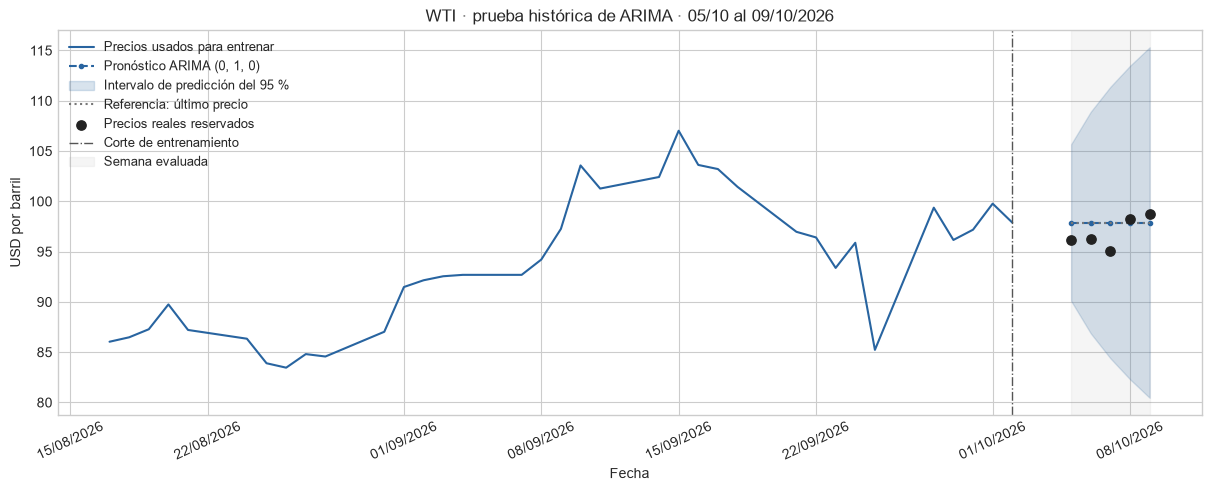

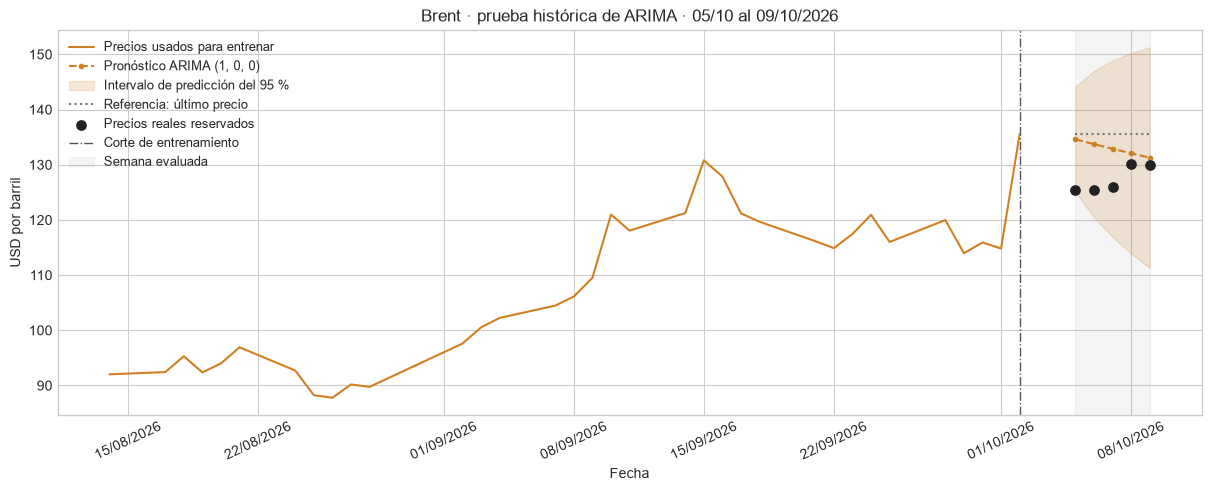

In [18]:
for crudo, datos_prueba in prueba_casos.items():
    entrenamiento = datos_prueba["entrenamiento"]
    futuro = datos_prueba["pronostico_completo"]
    reales = datos_prueba["reales"].dropna()
    color = COLORES[crudo]
    fig, ax = plt.subplots(figsize=(12, 4.8), constrained_layout=True)
    ax.plot(
        entrenamiento.index[-35:], entrenamiento.iloc[-35:],
        color=color, label="Precios usados para entrenar",
    )
    ax.plot(
        futuro.index, futuro["ARIMA"], color=color, linestyle="--",
        marker=".", label=f"Pronóstico ARIMA {datos_prueba['caso']['orden']}",
    )
    ax.fill_between(
        futuro.index, futuro["Inferior95"].to_numpy(dtype=float),
        futuro["Superior95"].to_numpy(dtype=float), color=color, alpha=0.18,
        label="Intervalo de predicción del 95 %",
    )
    ax.plot(
        futuro.index, futuro["Ultimo_precio"], color="#777777",
        linestyle=":", label="Referencia: último precio",
    )
    ax.scatter(
        reales.index, reales.to_numpy(), color="#222222", s=45, zorder=5,
        label="Precios reales reservados",
    )
    ax.axvline(
        datos_prueba["corte"], color="#555555", linestyle="-.", linewidth=1,
        label="Corte de entrenamiento",
    )
    ax.axvspan(
        datos_prueba["lunes"], datos_prueba["viernes"], color="#888888", alpha=0.08,
        label="Semana evaluada",
    )
    ax.set(
        title=f"{crudo} · prueba histórica de ARIMA · "
              f"{datos_prueba['lunes']:%d/%m} al {datos_prueba['viernes']:%d/%m/%Y}",
        xlabel="Fecha", ylabel="USD por barril",
    )
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
    ax.tick_params(axis="x", labelrotation=25)
    ax.legend(loc="best", fontsize=9)
    plt.show()

### 10.4. Lectura de la prueba

La lectura siguiente se recalcula con la semana elegida. La comparación describe exclusivamente las cotizaciones observadas en esa semana; no basta para concluir que un método será superior en otras semanas ni durante nuevos cambios del mercado.

Esta prueba utiliza un corte calendario y una semana concreta. La validación del punto 6 utiliza varios orígenes sobre cotizaciones consecutivas: sus métricas deben leerse con las fechas y el horizonte de cada experimento.

In [19]:
if prueba_metricas.empty:
    display(Markdown(
        "La prueba no generó métricas. Revisar los mensajes anteriores, la semana "
        "elegida y la cobertura de la fuente."
    ))
else:
    lecturas = []
    for crudo, grupo in prueba_metricas.groupby("Crudo", sort=False):
        por_modelo = grupo.set_index("Modelo")
        mae_arima = float(por_modelo.loc["ARIMA", "MAE (USD/barril)"])
        mae_ultimo = float(por_modelo.loc["Último precio", "MAE (USD/barril)"])
        n = int(por_modelo.loc["ARIMA", "Cotizaciones evaluadas"])
        estado = por_modelo.loc["ARIMA", "Evaluación"]
        diferencia = mae_arima - mae_ultimo
        if np.isclose(diferencia, 0.0, atol=1e-6):
            comparacion = "Los dos métodos tuvieron prácticamente el mismo MAE."
        elif diferencia < 0:
            comparacion = (
                f"ARIMA tuvo un MAE menor en {abs(diferencia):.3f} USD por barril."
            )
        else:
            comparacion = (
                f"La referencia del último precio tuvo un MAE menor en "
                f"{diferencia:.3f} USD por barril."
            )
        lecturas.append(
            f"- **{crudo}:** evaluación **{estado}**, con {n} de 5 cotizaciones. "
            f"MAE de ARIMA: **{mae_arima:.3f}** USD por barril; "
            f"MAE del último precio: **{mae_ultimo:.3f}**. {comparacion}"
        )
    lecturas.append(
        "Los errores describen esta única semana y la fuente disponible en esta ejecución. "
        "La selección y el ajuste se hicieron con datos anteriores al corte; "
        "los precios reales de la semana se utilizaron solamente para evaluar. "
        "Si la evaluación es parcial, sus errores resumen solo las fechas publicadas."
    )
    display(Markdown("\n\n".join(lecturas)))

- **WTI:** evaluación **COMPLETA**, con 5 de 5 cotizaciones. MAE de ARIMA: **1.498** USD por barril; MAE del último precio: **1.498**. Los dos métodos tuvieron prácticamente el mismo MAE.

- **Brent:** evaluación **COMPLETA**, con 5 de 5 cotizaciones. MAE de ARIMA: **5.485** USD por barril; MAE del último precio: **8.078**. ARIMA tuvo un MAE menor en 2.593 USD por barril.

Los errores describen esta única semana y la fuente disponible en esta ejecución. La selección y el ajuste se hicieron con datos anteriores al corte; los precios reales de la semana se utilizaron solamente para evaluar. Si la evaluación es parcial, sus errores resumen solo las fechas publicadas.

## Fuentes y reproducibilidad

- Datos: [EIA, precios spot diarios de petróleo](https://www.eia.gov/dnav/pet/pet_pri_spt_s1_d.htm); archivo y fecha de corte informados en los puntos 2 y 4.
- [ARIMA en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html) y [pronósticos e intervalos](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.get_forecast.html).
- [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html) y [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).
- Hyndman y Athanasopoulos: [ARIMA](https://otexts.com/fpp3/arima.html) y [evaluación temporal](https://otexts.com/fpp3/toolbox.html#time-series-cross-validation).

Las dependencias ya están contempladas en `requirements.txt`. Para reproducir una ejecución, conservar el mismo CSV, fijar `FECHA_REFERENCIA`, usar las versiones mostradas al comienzo y ejecutar todas las celdas en orden. Consultar EIA hoy puede devolver revisiones históricas que no estaban disponibles al corte: la prueba retrospectiva representa un recorte temporal de la fuente disponible, no una reconstrucción de publicaciones de cada fecha.

Este archivo no importa ni ejecuta los otros notebooks y no escribe archivos de datos. No se utiliza una partición aleatoria: el objetivo de evaluación es anticipar observaciones futuras respetando el orden temporal.